In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/raw/Kerala-Rainfall-Historical.csv")

# Display basic information
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

Dataset Shape: (117, 19)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 117 entries, 0 to 116
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  117 non-null    str    
 1   YEAR         117 non-null    int64  
 2   JAN          117 non-null    float64
 3   FEB          117 non-null    float64
 4   MAR          117 non-null    float64
 5   APR          117 non-null    float64
 6   MAY          117 non-null    float64
 7   JUN          117 non-null    float64
 8   JUL          117 non-null    float64
 9   AUG          117 non-null    float64
 10  SEP          117 non-null    float64
 11  OCT          117 non-null    float64
 12  NOV          117 non-null    float64
 13  DEC          117 non-null    float64
 14  ANNUAL       117 non-null    float64
 15  JF           117 non-null    float64
 16  MAM          117 non-null    float64
 17  JJAS         117 non-null    float64
 18  OND          1

In [3]:
# 1. Check for duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 2. Check for duplicate years
print("Duplicate years:", df["YEAR"].duplicated().sum())

# 3. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Check unique subdivisions
print("\nSubdivisions:")
print(df["SUBDIVISION"].unique())

# 5. Check year range
print("\nYear Range:")
print(df["YEAR"].min(), "to", df["YEAR"].max())

# 6. Check descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe().round(2))

Duplicate rows: 0
Duplicate years: 0

Missing Values:
SUBDIVISION    0
YEAR           0
JAN            0
FEB            0
MAR            0
APR            0
MAY            0
JUN            0
JUL            0
AUG            0
SEP            0
OCT            0
NOV            0
DEC            0
ANNUAL         0
JF             0
MAM            0
JJAS           0
OND            0
dtype: int64

Subdivisions:
<StringArray>
['Kerala']
Length: 1, dtype: str

Year Range:
1901 to 2017

Descriptive Statistics:


,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
count,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00,117.00
mean,1959.00,12.17,15.37,37.13,109.42,229.98,653.16,695.98,420.69,245.86,291.94,162.56,39.98,2914.25,27.54,376.52,2015.69,494.48
std,33.92,15.43,16.13,30.46,45.17,148.01,186.22,226.57,159.34,123.27,95.06,83.73,36.82,430.29,22.22,149.91,388.18,132.03
min,1901.00,0.00,0.00,0.10,13.10,53.40,196.80,167.50,178.60,41.30,68.50,31.50,0.10,1870.90,0.30,89.90,1104.30,166.60
25%,1930.00,2.40,4.70,18.10,71.50,124.50,541.70,532.00,315.30,150.10,221.60,92.90,10.20,2621.70,10.30,277.80,1749.20,406.50
50%,1959.00,6.00,8.40,28.30,108.40,190.60,625.80,687.30,385.20,223.90,282.60,153.00,31.10,2931.10,20.50,342.00,1947.50,500.80
75%,1988.00,16.90,21.40,50.10,135.10,265.40,788.50,831.60,495.00,335.60,354.10,219.10,54.10,3151.50,40.60,436.90,2231.20,584.00
max,2017.00,83.50,79.00,217.20,238.00,738.80,1098.20,1526.50,1199.20,526.70,567.90,365.60,202.30,4257.80,98.10,915.20,3451.30,823.30


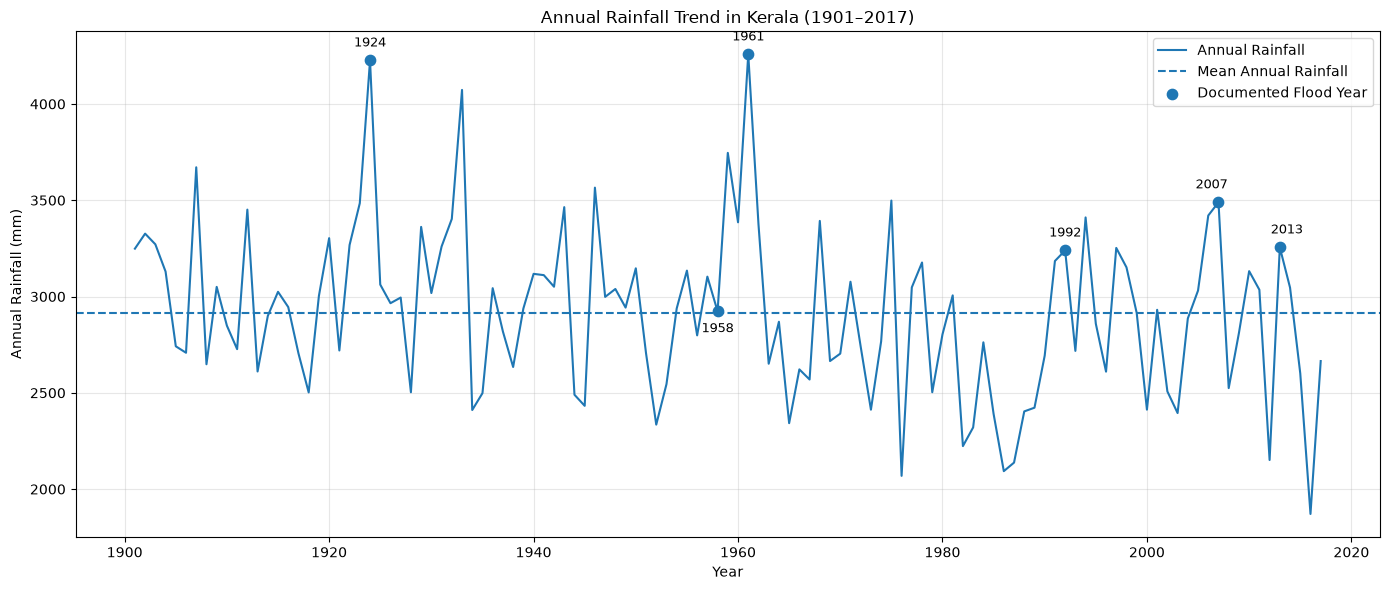

Flood years annotated: [1924, 1958, 1961, 1992, 2007, 2013]
Figure 1 saved successfully!


In [4]:
# Annual rainfall trend with documented flood-year annotations

from pathlib import Path

# Load documented flood-year evidence
flood_evidence = pd.read_csv(
    "../data/raw/flood_year_evidence.csv"
)

flood_years = flood_evidence.loc[
    flood_evidence["FLOOD_LABEL"] == 1, "YEAR"
].astype(int).tolist()

# Identify corresponding observations
flood_data = df[df["YEAR"].isin(flood_years)]

plt.figure(figsize=(14, 6))

plt.plot(
    df["YEAR"],
    df["ANNUAL"],
    linewidth=1.5,
    label="Annual Rainfall"
)

plt.axhline(
    df["ANNUAL"].mean(),
    linestyle="--",
    label="Mean Annual Rainfall"
)

# Mark documented flood years
plt.scatter(
    flood_data["YEAR"],
    flood_data["ANNUAL"],
    s=55,
    marker="o",
    label="Documented Flood Year",
    zorder=3
)

# Annotate each flood year
offsets = {
    1924: (0, 10),
    1958: (0, -15),
    1961: (0, 10),
    1992: (0, 10),
    2007: (-5, 10),
    2013: (5, 10)
}

for _, row in flood_data.iterrows():
    year = int(row["YEAR"])

    plt.annotate(
        str(year),
        (year, row["ANNUAL"]),
        xytext=offsets.get(year, (0, 10)),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

plt.title("Annual Rainfall Trend in Kerala (1901–2017)")
plt.xlabel("Year")
plt.ylabel("Annual Rainfall (mm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "annual_rainfall_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Flood years annotated:", sorted(flood_years))
print("Figure 1 saved successfully!")

#### Observation: Annual Rainfall Trend

The annual rainfall trend in Kerala from 1901 to 2017 shows considerable year-to-year variability. Several years recorded rainfall substantially above or below the historical mean of approximately 2914.25 mm.

The visualisation does not indicate an obvious consistent long-term increasing trend. Instead, rainfall appears to fluctuate considerably across the observation period.

This variability highlights the importance of investigating historical rainfall patterns when studying flood-year classification.

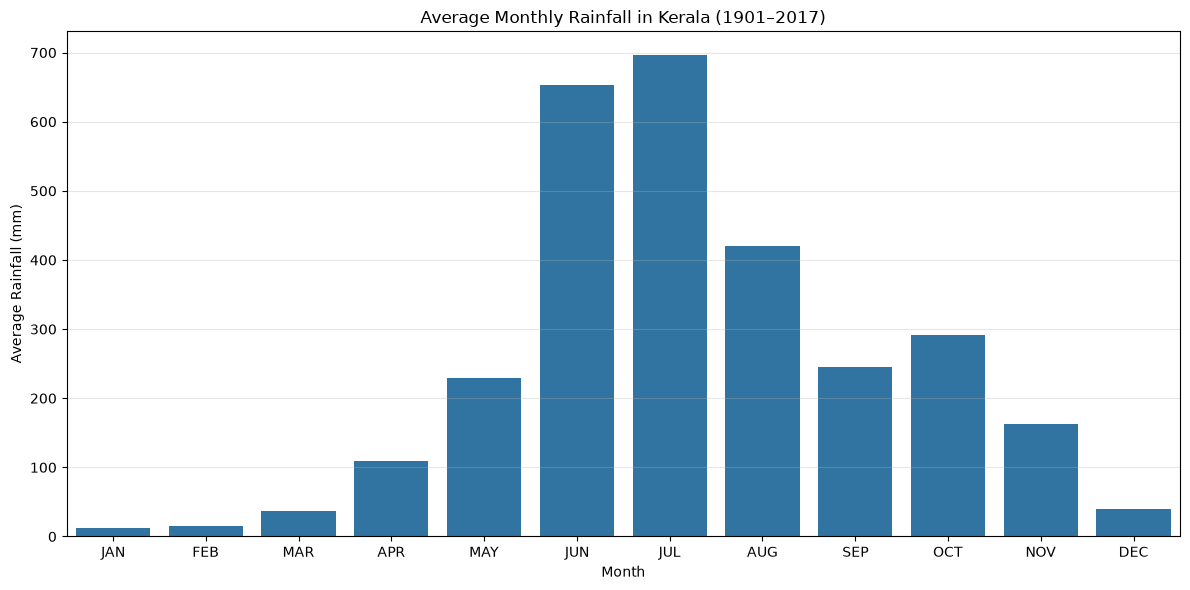

In [5]:
# Calculate average rainfall for each month

monthly_columns = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

monthly_avg = df[monthly_columns].mean()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_avg.index,
    y=monthly_avg.values
)

plt.title("Average Monthly Rainfall in Kerala (1901–2017)")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#### Observation: Monthly Rainfall Distribution

The monthly rainfall distribution indicates a strong seasonal pattern in Kerala. Rainfall increases considerably from April and reaches its highest average values during June and July.

July records the highest average monthly rainfall, followed by June. Rainfall gradually decreases after July, although substantial precipitation continues during August, September and October.

The relatively low rainfall during January and February contrasts with the heavy monsoon months. This seasonal variation highlights the importance of monsoon rainfall in understanding Kerala's historical rainfall patterns.


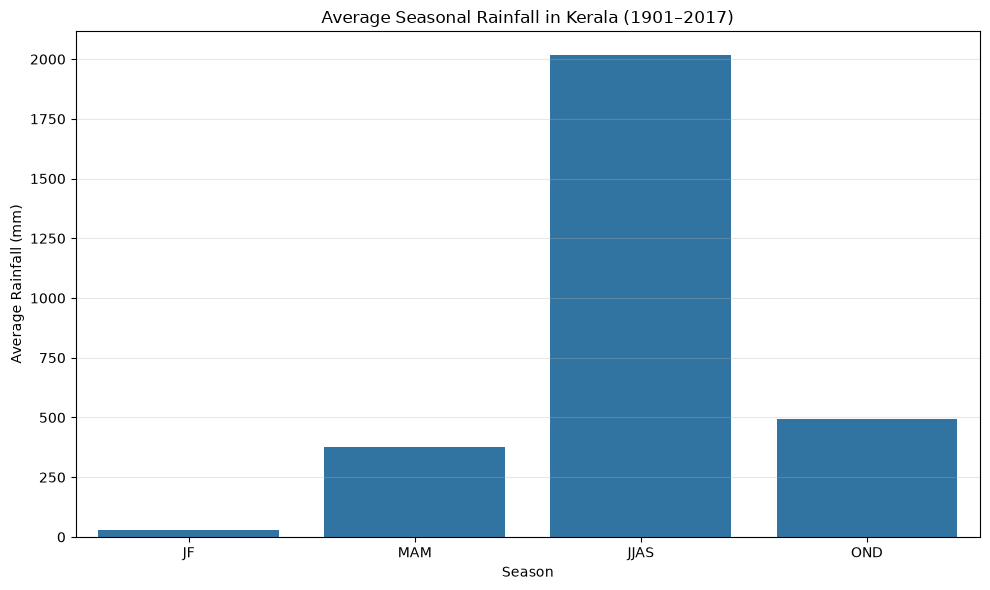

In [6]:
# Calculate average seasonal rainfall

seasonal_columns = ["JF", "MAM", "JJAS", "OND"]

seasonal_avg = df[seasonal_columns].mean()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=seasonal_avg.index,
    y=seasonal_avg.values
)

plt.title("Average Seasonal Rainfall in Kerala (1901–2017)")
plt.xlabel("Season")
plt.ylabel("Average Rainfall (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Observation: Seasonal Rainfall Distribution

The seasonal rainfall distribution demonstrates that June–September (JJAS) is the dominant rainfall season in Kerala, with an average rainfall of approximately 2015.69 mm.

October–December (OND) contributes the second largest seasonal rainfall, followed by March–May (MAM). January–February (JF) records the lowest average rainfall.

The findings highlight the substantial contribution of the southwest monsoon to Kerala's annual rainfall and support further investigation of monsoon rainfall patterns for flood-year classification.

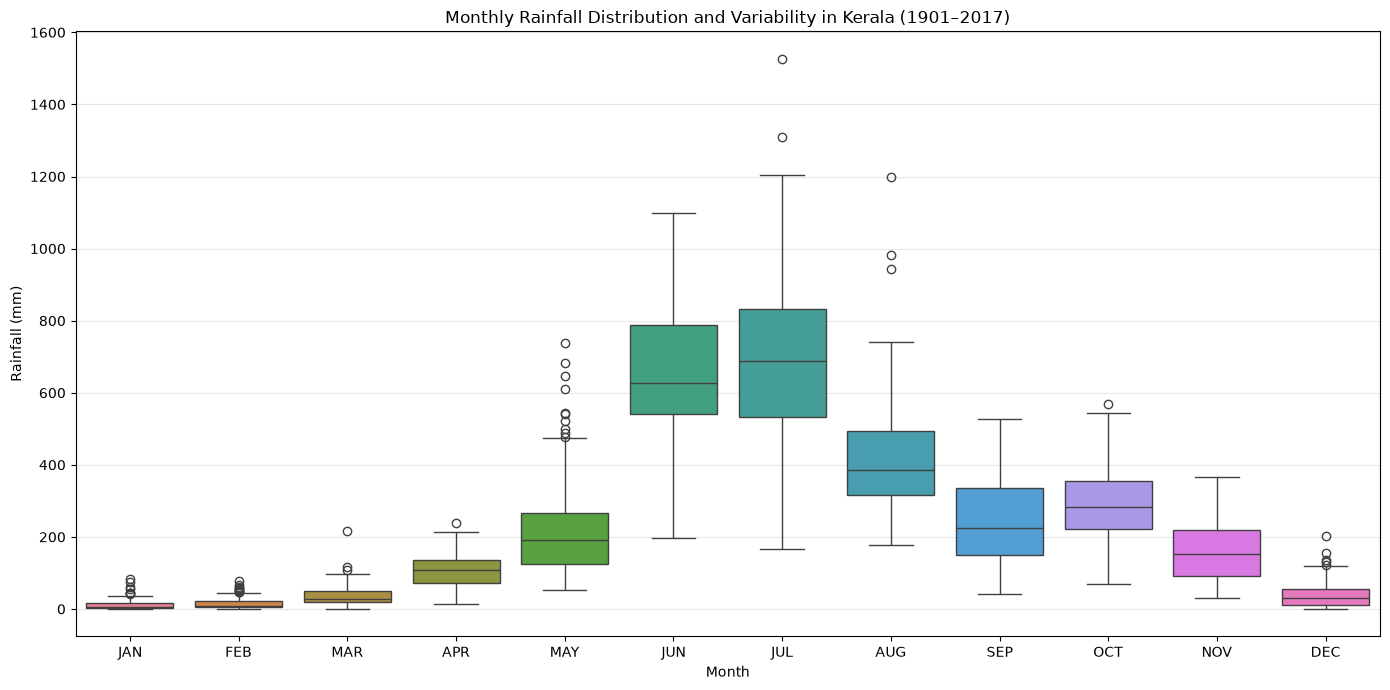

In [7]:
# Monthly rainfall variability using boxplots

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[monthly_columns])

plt.title("Monthly Rainfall Distribution and Variability in Kerala (1901–2017)")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Observation: Monthly Rainfall Variability

The boxplot illustrates considerable variation in monthly rainfall across Kerala between 1901 and 2017.

June and July exhibit higher rainfall levels and wider distributions compared with most other months. Several potential outliers are also observed, particularly during May, July and August.

These extreme observations may represent unusually high rainfall events and are potentially relevant to the study of flood-year classification. Therefore, they will not be removed automatically during preprocessing.


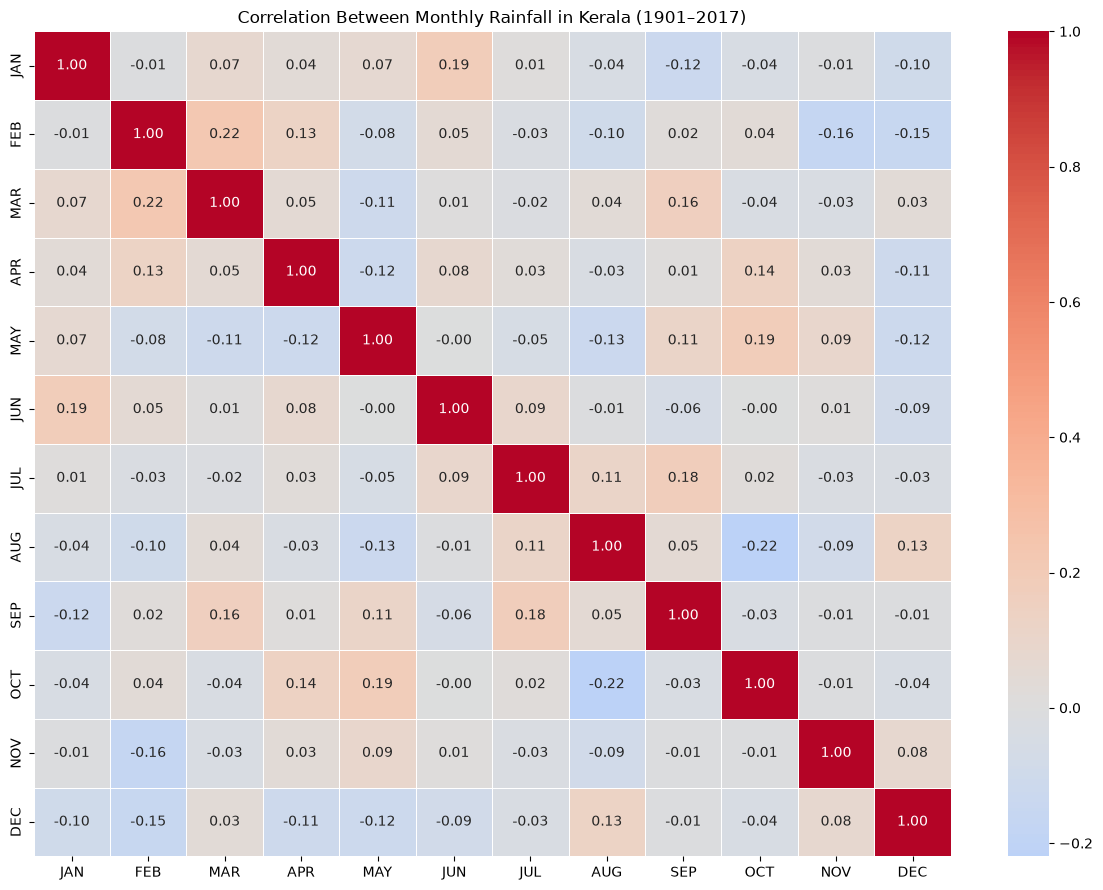

In [8]:
# Correlation between monthly rainfall variables

monthly_corr = df[monthly_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    monthly_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Between Monthly Rainfall in Kerala (1901–2017)")
plt.tight_layout()
plt.show()

#### Observation: Correlation Analysis

The correlation heatmap indicates generally weak linear relationships between individual monthly rainfall variables across the observation period.

The strongest positive correlation is observed between February and March, at approximately 0.22, while the strongest negative correlation is between August and October, at approximately -0.22.

Most monthly rainfall pairs exhibit correlation values relatively close to zero. This suggests that individual monthly rainfall measurements generally show limited pairwise linear association.

However, weak correlation does not necessarily indicate that a feature lacks predictive value. The usefulness of individual months and their combinations will be evaluated during model development.

In [9]:
# Final monthly rainfall summary

monthly_summary = df[monthly_columns].agg(
    ["mean", "median", "std", "min", "max"]
).T

monthly_summary = monthly_summary.round(2)

display(monthly_summary)

# Identify months with highest and lowest average rainfall
highest_month = monthly_summary["mean"].idxmax()
lowest_month = monthly_summary["mean"].idxmin()

print("Highest average rainfall month:", highest_month)
print("Lowest average rainfall month:", lowest_month)

# Identify month with greatest rainfall variability
most_variable_month = monthly_summary["std"].idxmax()

print("Month with greatest rainfall variability:", most_variable_month)

,mean,median,std,min,max
JAN,12.17,6.0,15.43,0.0,83.5
FEB,15.37,8.4,16.13,0.0,79.0
MAR,37.13,28.3,30.46,0.1,217.2
APR,109.42,108.4,45.17,13.1,238.0
MAY,229.98,190.6,148.01,53.4,738.8
JUN,653.16,625.8,186.22,196.8,1098.2
JUL,695.98,687.3,226.57,167.5,1526.5
AUG,420.69,385.2,159.34,178.6,1199.2
SEP,245.86,223.9,123.27,41.3,526.7
OCT,291.94,282.6,95.06,68.5,567.9


Highest average rainfall month: JUL
Lowest average rainfall month: JAN
Month with greatest rainfall variability: JUL


In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# 1. Monthly rainfall
plt.figure(figsize=(10, 5))
monthly_avg = df[monthly_columns].mean()
sns.barplot(x=monthly_avg.index, y=monthly_avg.values)
plt.title("Average Monthly Rainfall")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig(figure_dir / "monthly_rainfall.png", dpi=300)
plt.close()

# 2. Seasonal rainfall
plt.figure(figsize=(8, 5))
seasonal_avg = df[["JF", "MAM", "JJAS", "OND"]].mean()
sns.barplot(x=seasonal_avg.index, y=seasonal_avg.values)
plt.title("Average Seasonal Rainfall")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig(figure_dir / "seasonal_rainfall.png", dpi=300)
plt.close()

# 3. Monthly variability
plt.figure(figsize=(11, 5))
sns.boxplot(data=df[monthly_columns])
plt.title("Monthly Rainfall Variability")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig(figure_dir / "monthly_boxplot.png", dpi=300)
plt.close()

# 4. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[monthly_columns].corr(), annot=True,
            cmap="coolwarm", fmt=".2f", center=0)
plt.title("Monthly Rainfall Correlation")
plt.tight_layout()
plt.savefig(figure_dir / "rainfall_correlation.png", dpi=300)
plt.close()

print("All five EDA figures exported successfully!")

All five EDA figures exported successfully!


#### Rainfall Comparison: Documented Flood Years vs Other Years

This analysis compares southwest monsoon (JJAS) and annual rainfall between documented major flood years and years not listed in the selected chronology.

The comparison provides a descriptive understanding of historical rainfall patterns associated with the target classification.

JJAS                           ANNUAL           \
                       count     mean   median     std  count     mean   
Year Group                                                               
Documented major flood     6  2711.92  2624.85  551.75      6  3565.30   
Not listed               111  1978.05  1939.20  342.34    111  2879.05   

                                        
                        median     std  
Year Group                              
Documented major flood  3372.5  554.43  
Not listed              2899.1  396.12

Documented flood years: [1924, 1958, 1961, 1992, 2007, 2013]
Flood years above the 90th percentile of JJAS rainfall: 4 out of 6


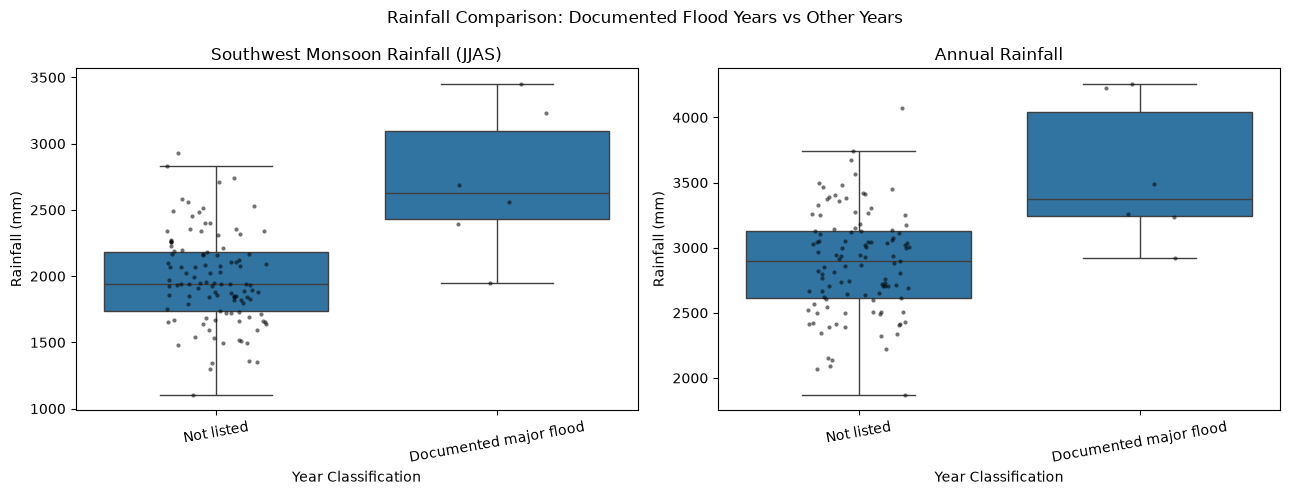

EDA comparison figure saved successfully!


In [11]:
# Compare rainfall in documented flood years and other years

from pathlib import Path

# Load documented flood-year evidence
flood_evidence = pd.read_csv(
    "../data/raw/flood_year_evidence.csv"
)

flood_years = flood_evidence.loc[
    flood_evidence["FLOOD_LABEL"] == 1,
    "YEAR"
].astype(int).tolist()

# Create a labelled comparison dataset
comparison_df = df.copy()

comparison_df["FLOOD_LABEL"] = (
    comparison_df["YEAR"]
    .astype(int)
    .isin(flood_years)
    .astype(int)
)

comparison_df["Year Group"] = comparison_df[
    "FLOOD_LABEL"
].map({
    0: "Not listed",
    1: "Documented major flood"
})

# Display descriptive statistics
group_summary = comparison_df.groupby(
    "Year Group",
    observed=True
)[["JJAS", "ANNUAL"]].agg(
    ["count", "mean", "median", "std"]
).round(2)

display(group_summary)

# Calculate the percentage rank of JJAS rainfall
comparison_df["JJAS_Percentile"] = (
    comparison_df["JJAS"].rank(pct=True) * 100
)

flood_comparison = comparison_df[
    comparison_df["FLOOD_LABEL"] == 1
]

above_90 = (
    flood_comparison["JJAS_Percentile"] > 90
).sum()

print("Documented flood years:", sorted(flood_years))
print(
    "Flood years above the 90th percentile of JJAS rainfall:",
    above_90,
    "out of",
    len(flood_years)
)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

rainfall_features = [
    ("JJAS", "Southwest Monsoon Rainfall (JJAS)"),
    ("ANNUAL", "Annual Rainfall")
]

for ax, (feature, title) in zip(axes, rainfall_features):

    sns.boxplot(
        data=comparison_df,
        x="Year Group",
        y=feature,
        ax=ax,
        showfliers=False
    )

    sns.stripplot(
        data=comparison_df,
        x="Year Group",
        y=feature,
        ax=ax,
        color="black",
        alpha=0.55,
        size=3,
        jitter=0.18
    )

    ax.set_title(title)
    ax.set_xlabel("Year Classification")
    ax.set_ylabel("Rainfall (mm)")
    ax.tick_params(axis="x", rotation=10)

plt.suptitle(
    "Rainfall Comparison: Documented Flood Years vs Other Years"
)

plt.tight_layout()

# Save figure
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "flood_vs_nonflood_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("EDA comparison figure saved successfully!")

#### Monthly Rainfall Comparison: Documented Flood Years vs Other Years

This analysis examines monthly rainfall distributions in documented major flood years and years not listed in the selected flood chronology.

The comparison focuses on January to September, corresponding to the prediction cutoffs investigated during model development.

Descriptive statistics and visualisations are used to explore whether rainfall patterns differ between the two groups across individual months.

Monthly comparison dataset: (1053, 5)

Observations by group:


Year Group
Documented major flood     54
Not listed                999
dtype: int64

,Month,Year Group,Count,Mean,Median,Std,Minimum,Maximum
0,JAN,Documented major flood,6,7.37,4.15,7.42,0.5,19.3
1,JAN,Not listed,111,12.43,6.40,15.72,0.0,83.5
2,FEB,Documented major flood,6,16.68,12.45,16.31,0.9,40.1
3,FEB,Not listed,111,15.30,8.40,16.19,0.0,79.0
4,MAR,Documented major flood,6,32.10,30.65,29.02,0.1,66.6
5,MAR,Not listed,111,37.40,28.30,30.64,0.9,217.2
6,APR,Documented major flood,6,95.17,102.55,41.35,43.0,138.5
7,APR,Not listed,111,110.19,108.40,45.41,13.1,238.0
8,MAY,Documented major flood,6,261.63,205.55,140.13,119.3,500.5
9,MAY,Not listed,111,228.27,180.60,148.84,53.4,738.8


Year Group,Documented major flood,Not listed,Flood_minus_not_listed
Month,,,
JAN,7.37,12.43,-5.06
FEB,16.68,15.30,1.38
MAR,32.10,37.40,-5.30
APR,95.17,110.19,-15.02
MAY,261.63,228.27,33.36
JUN,883.02,640.74,242.28
JUL,976.67,680.81,295.86
AUG,532.70,414.64,118.06
SEP,319.55,241.88,77.67


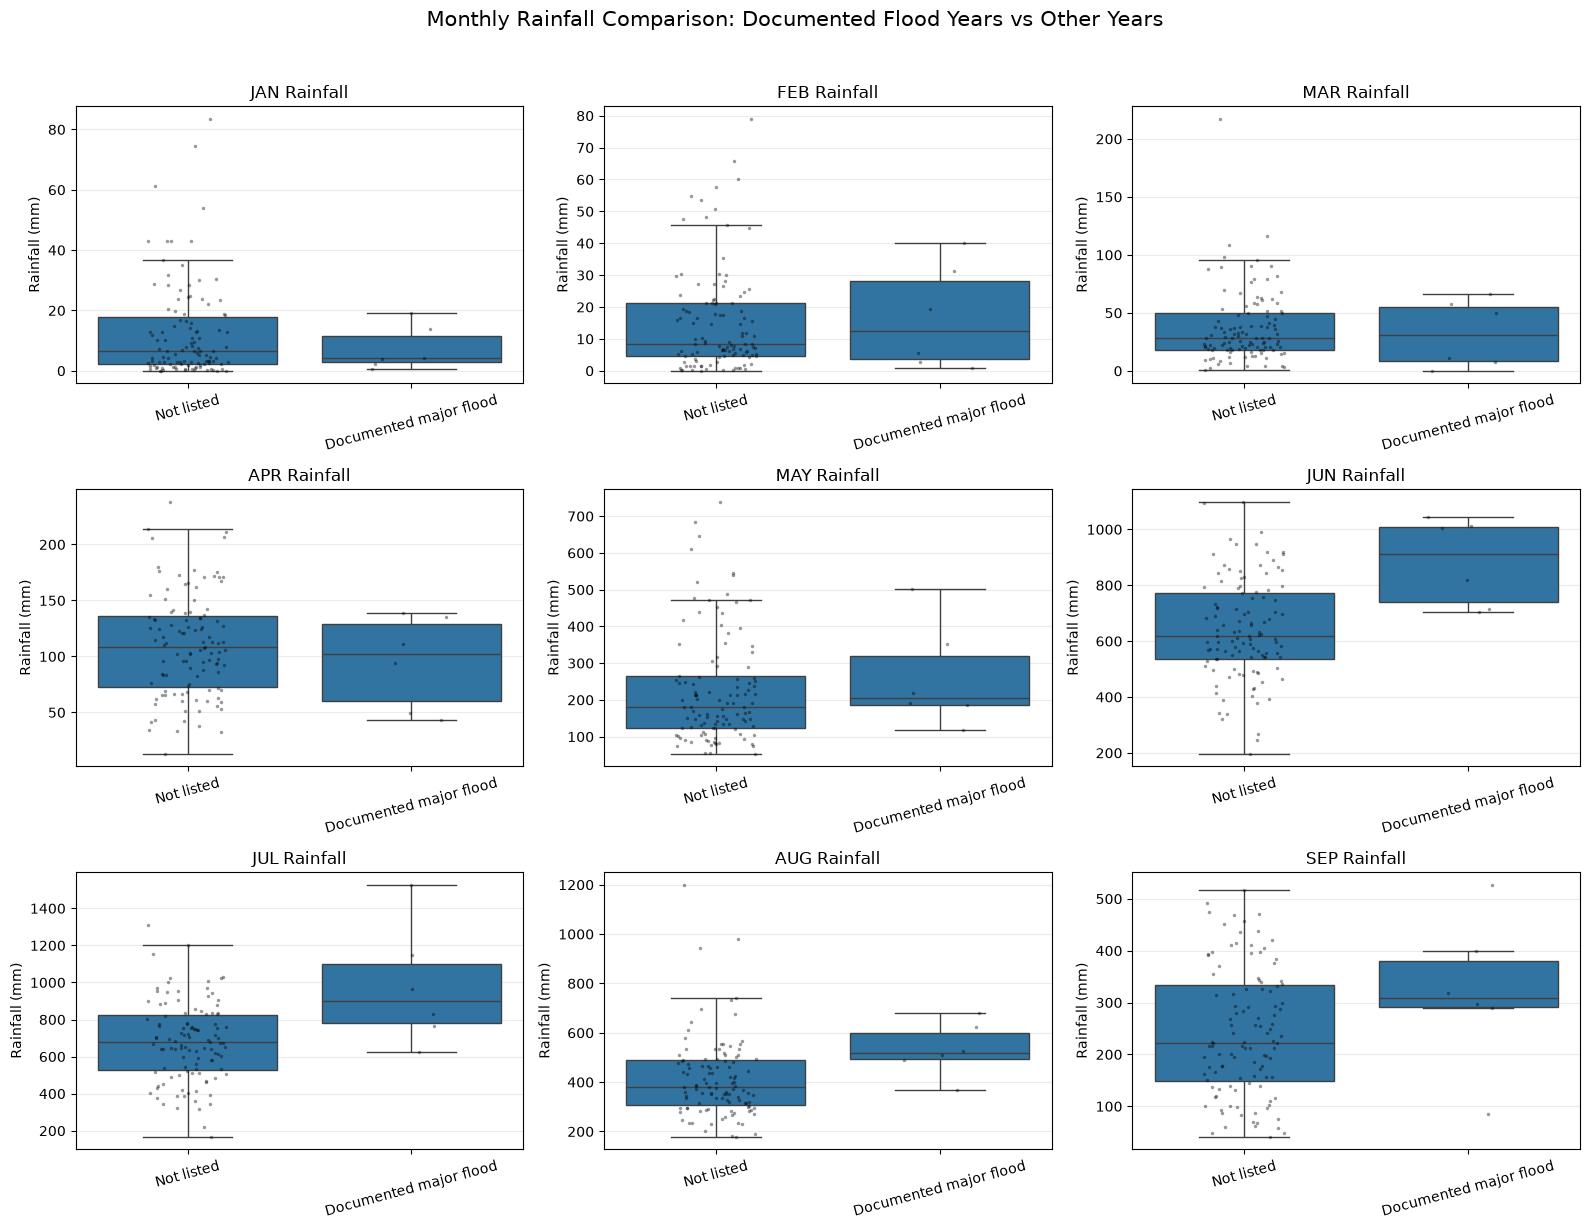


Monthly rainfall comparison completed!
Figure and statistical outputs saved successfully.


In [12]:
# MONTHLY RAINFALL COMPARISON:
# DOCUMENTED FLOOD YEARS VS OTHER YEARS

from pathlib import Path

# Months relevant to the prediction cutoffs
prediction_months = [
    "JAN", "FEB", "MAR", "APR", "MAY",
    "JUN", "JUL", "AUG", "SEP"
]

group_order = [
    "Not listed",
    "Documented major flood"
]

# Validate the comparison dataset
assert len(comparison_df) == 117
assert comparison_df["YEAR"].nunique() == 117
assert comparison_df["FLOOD_LABEL"].sum() == 6

assert all(
    month in comparison_df.columns
    for month in prediction_months
)

# Convert monthly rainfall data into long format
monthly_long = comparison_df.melt(
    id_vars=["YEAR", "FLOOD_LABEL", "Year Group"],
    value_vars=prediction_months,
    var_name="Month",
    value_name="Rainfall"
)

# Preserve chronological month order
monthly_long["Month"] = pd.Categorical(
    monthly_long["Month"],
    categories=prediction_months,
    ordered=True
)

# Verify the transformed dataset
assert monthly_long["Rainfall"].notna().all()

print("Monthly comparison dataset:", monthly_long.shape)
print("\nObservations by group:")
display(
    monthly_long.groupby(
        "Year Group",
        observed=True
    ).size()
)

# Calculate descriptive statistics
monthly_group_summary = (
    monthly_long
    .groupby(
        ["Month", "Year Group"],
        observed=True
    )["Rainfall"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Minimum="min",
        Maximum="max"
    )
    .round(2)
    .reset_index()
)

display(monthly_group_summary)

# Compare mean rainfall between the two groups
monthly_mean_comparison = monthly_long.pivot_table(
    index="Month",
    columns="Year Group",
    values="Rainfall",
    aggfunc="mean",
    observed=True
)

monthly_mean_comparison["Flood_minus_not_listed"] = (
    monthly_mean_comparison["Documented major flood"]
    - monthly_mean_comparison["Not listed"]
)

display(monthly_mean_comparison.round(2))

# Create monthly comparison visualisations
fig, axes = plt.subplots(
    3, 3,
    figsize=(16, 12)
)

axes = axes.flatten()

for ax, month in zip(axes, prediction_months):

    month_data = monthly_long[
        monthly_long["Month"] == month
    ]

    sns.boxplot(
        data=month_data,
        x="Year Group",
        y="Rainfall",
        order=group_order,
        showfliers=False,
        ax=ax
    )

    # Display individual observations
    sns.stripplot(
        data=month_data,
        x="Year Group",
        y="Rainfall",
        order=group_order,
        color="black",
        alpha=0.4,
        size=2.5,
        jitter=0.18,
        ax=ax
    )

    ax.set_title(f"{month} Rainfall")
    ax.set_xlabel("")
    ax.set_ylabel("Rainfall (mm)")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)

plt.suptitle(
    "Monthly Rainfall Comparison: "
    "Documented Flood Years vs Other Years",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

# Save the figure
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "monthly_flood_vs_nonflood_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save descriptive statistics
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

monthly_group_summary.to_csv(
    output_dir / "monthly_flood_rainfall_summary.csv",
    index=False
)

monthly_mean_comparison.to_csv(
    output_dir / "monthly_flood_mean_comparison.csv"
)

print("\nMonthly rainfall comparison completed!")
print("Figure and statistical outputs saved successfully.")

#### Observations: Monthly Rainfall Comparison

The monthly comparison reveals differences in rainfall patterns between documented major flood years and years not listed in the selected chronology.

January to April show relatively small differences in average rainfall, with documented flood years recording lower average rainfall in these months.

From May onwards, the average rainfall in documented flood years becomes higher. The largest differences are observed in June and July, where the mean rainfall is approximately 242 mm and 296 mm higher, respectively, than in years not listed in the chronology.

August and September also show higher average rainfall in documented flood years.

However, the boxplots indicate that the monthly rainfall distributions are not completely separated. The results are descriptive and should be interpreted cautiously because only six documented flood years are available.

These observations provide further motivation for investigating the contribution of early monsoon rainfall to historical flood-year classification.

#### Individual Flood-Year Rainfall Profile

This analysis examines monthly and seasonal rainfall patterns for each of the six documented major flood years.

The rainfall values are compared with their empirical percentile positions within the complete historical rainfall record.

This provides a closer examination of differences between individual flood years and helps identify cases that do not follow the overall rainfall patterns observed in the group comparison.

In [13]:
# INDIVIDUAL FLOOD-YEAR RAINFALL PROFILE

# Select the documented flood-year observations
profile_columns = [
    "YEAR", "MAR", "MAY", "JUN",
    "JUL", "SEP", "JJAS", "ANNUAL"
]

flood_year_profile = (
    comparison_df.loc[
        comparison_df["FLOOD_LABEL"] == 1,
        profile_columns
    ]
    .sort_values("YEAR")
    .reset_index(drop=True)
)

# Add event descriptions
flood_year_profile = flood_year_profile.merge(
    flood_evidence[["YEAR", "EVENT_DESCRIPTION"]],
    on="YEAR",
    how="left",
    validate="one_to_one"
)

# Calculate empirical percentile ranks using all 117 years
percentile_features = [
    "JUN", "JUL", "JJAS", "ANNUAL"
]

all_year_percentiles = (
    comparison_df
    .set_index("YEAR")[percentile_features]
    .rank(pct=True) * 100
)

for feature in percentile_features:

    flood_year_profile[f"{feature}_PERCENTILE"] = (
        flood_year_profile["YEAR"]
        .map(all_year_percentiles[feature])
        .round(2)
    )

# Verify the profile
assert len(flood_year_profile) == 6

assert set(
    flood_year_profile["YEAR"]
) == set(flood_years)

assert flood_year_profile["EVENT_DESCRIPTION"].notna().all()

display(
    flood_year_profile.round(2)
)

# Save the individual flood-year profile
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

flood_year_profile.to_csv(
    output_dir / "individual_flood_year_profile.csv",
    index=False
)

print("Flood years analysed:", len(flood_year_profile))
print("Flood-year profile saved successfully!")

,YEAR,MAR,MAY,JUN,JUL,SEP,JJAS,ANNUAL,EVENT_DESCRIPTION,JUN_PERCENTILE,JUL_PERCENTILE,JJAS_PERCENTILE,ANNUAL_PERCENTILE
0,1924,66.6,185.4,1011.7,1526.5,289.1,3451.3,4226.4,Major statewide flood,97.44,100.00,100.00,99.15
1,1958,57.3,353.5,713.3,622.7,86.1,1948.7,2923.1,Flash floods in multiple river systems,65.81,35.04,51.28,49.57
2,1961,11.4,500.5,1005.2,1146.5,399.3,3229.3,4257.8,Severe statewide flooding,96.58,96.58,99.15,100.00
3,1992,0.1,218.4,819.3,767.8,297.5,2392.5,3239.5,Flooding in southern Kerala districts,79.49,67.52,85.47,77.78
4,2007,7.3,192.7,705.9,966.3,526.7,2688.5,3489.6,Flooding across multiple Kerala districts,64.96,89.74,94.87,94.02
5,2013,49.9,119.3,1042.7,830.2,318.6,2561.2,3255.4,Heavy rainfall and dam release in Periyar Basin,98.29,74.36,93.16,80.34


Flood years analysed: 6
Flood-year profile saved successfully!


#### Observations: Individual Flood-Year Rainfall Profiles

The individual rainfall profiles reveal considerable variation among the six documented major flood years.

The years 1924 and 1961 recorded exceptionally high June, July and JJAS rainfall, with their southwest monsoon rainfall ranking at or above the 99th percentile of the historical distribution.

The years 2007 and 2013 also recorded high JJAS rainfall, although their monthly rainfall profiles differed. In 2007, July rainfall was particularly high, whereas 2013 recorded exceptionally high June rainfall.

The 1992 flood year had relatively elevated rainfall but did not exceed the 90th percentile of JJAS rainfall.

An important exception is 1958, whose JJAS rainfall ranked around the 51st percentile. Despite being documented as a major flood year, its aggregate southwest monsoon rainfall was close to the historical median.

These observations demonstrate that documented flood years do not necessarily share a uniform monthly rainfall pattern. Rainfall totals alone may therefore be insufficient to distinguish all major flood years.